 - data should be linear seprable
 - it's genral equation AX+BX+C = 0
 - so our end objective is to find A B C
### How i works 
 - start with random values of A B C
 - then select random  piont  and check according to that piont wether our our A B C 's line is coorect  or not
 - and then try different point do iteration of line with different values of AB&C
 - moslty you have to run 1000 to 10000 time loop for it
 - convergenace : where not any point is  mis classified 

## we will see through preceptron trick

In [1]:
from sklearn.datasets import make_classification
import numpy as np 
import pandas as pd 
X,y = make_classification(n_samples=100,n_features=2,n_informative=1,n_redundant=0,n_classes=2,n_clusters_per_class=1,random_state=41,hypercube=False,class_sep=10)

In [2]:
import matplotlib.pyplot as plt 

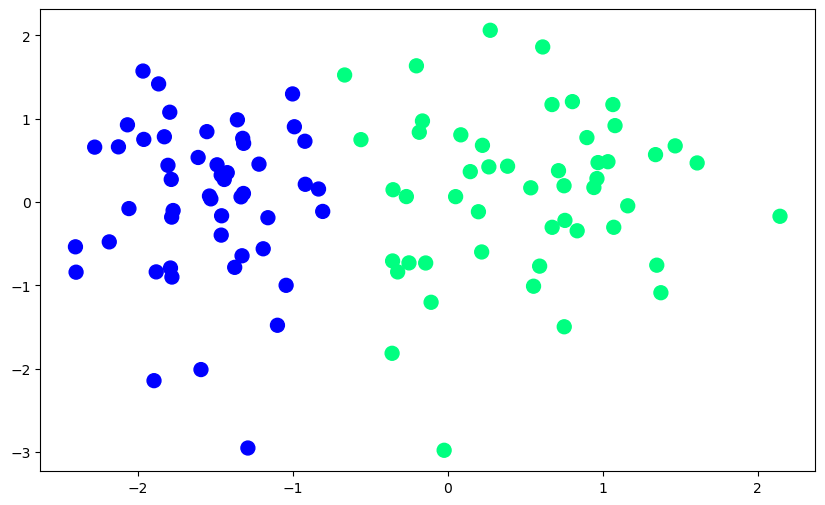

In [3]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [4]:
def percepton(X,y):
    X= np.insert(X,0,1,axis=1)
    weights =np.ones(X.shape[1])
    lr=0.1

    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights= weights + lr*(y[j]-y_hat)*X[j]
    return weights[0],weights[1:]

In [5]:
def step(z):
    return 1 if z>0 else 0 

In [6]:
intercept_,coef_=percepton(X,y)

In [7]:

print(coef_)
print(intercept_)

[1.36432956 0.0514514 ]
0.9


In [8]:
m = -(coef_[0]/coef_[1])
b= -(intercept_/coef_[1])

In [9]:
x_input=np.linspace(-3,3,100)
y_input =m*x_input+b

(-3.0, 2.0)

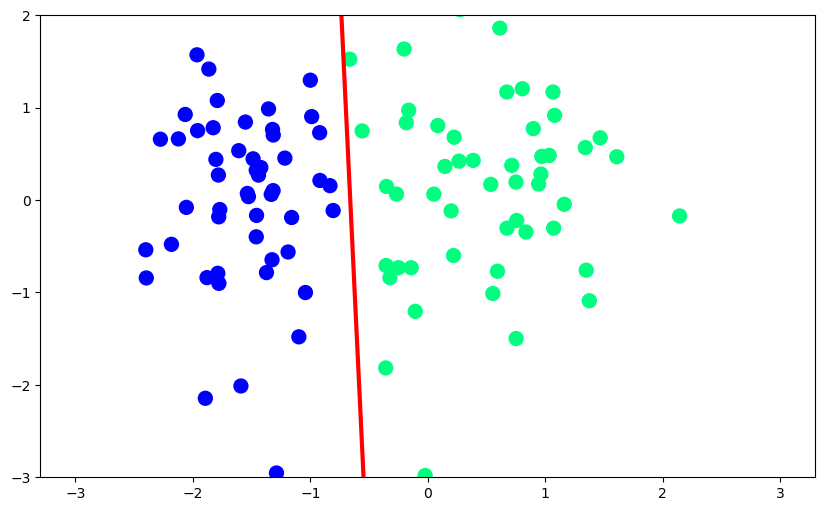

In [10]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

In [11]:
# logisticregression of skit learn truess to attempt best  place  which them by easily differentiable but make  cpercetron will stop imediate after   classification dont try to find best line 

 - let's this piont by using skitlearn's logistic regression

In [12]:
from sklearn.linear_model import LogisticRegression
lor = LogisticRegression()
lor.fit(X,y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [13]:
m=-(lor.coef_[0][0]/lor.coef_[0][1])
b=-(lor.intercept_/lor.coef_[0][1]) 

In [14]:
x_input1=np.linspace(-3,3,100)
y_input1=m*x_input+b

(-3.0, 2.0)

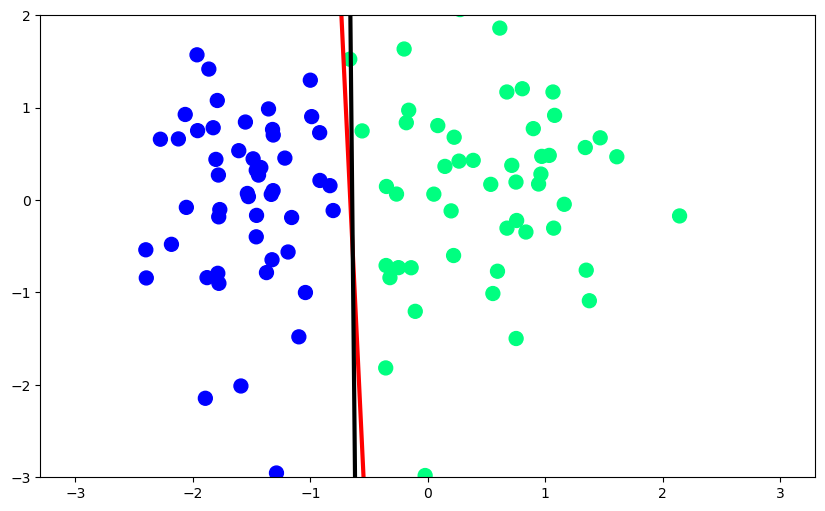

In [15]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.plot(x_input1,y_input1,color='black',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

 - we will pull the line if this is point is incorrect and push if  line is correct to improve the line of perceptron
 - the larger the distance greater the pull and push
 - sigmoid function to avioid ((y-y^)=0|1) : sigmiod scless larger values function to 0 to 1 values
 - sigmiod will give entire system probabi;listic interpretatioin
   

In [16]:
def sigmoid (z):
    return 1/(1+np.exp(-z))

In [17]:
def percepton(X,y):
    X= np.insert(X,0,1,axis=1)
    weights =np.ones(X.shape[1])
    lr=0.1

    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = sigmoid(np.dot(X[j],weights))
        weights= weights + lr*(y[j]-y_hat)*X[j]
    return weights[0],weights[1:]

In [18]:
intercept_,coef_ =percepton(X,y)

In [19]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

In [20]:
x_input2 =np.linspace(-3,3,100)
y_input2 =m*x_input + b

(-3.0, 2.0)

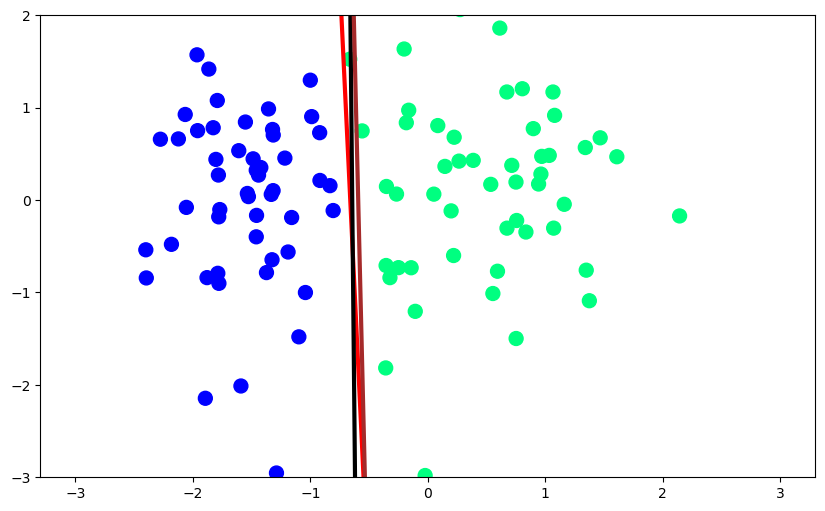

In [21]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.plot(x_input1,y_input1,color='black',linewidth=3)
plt.plot(x_input2,y_input2,color='brown',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

# in above plot you can see still is not that well so nowe we see how to improvesigmoid as well here - red line is for step function ,brown for sigmoid function and and black forskitlearn logistic regression

In [22]:
# like most solution of most ML problem  we have find loss or error function for it  and then we will slect minima or minimum values solution in order to get least error 

Below is the **complete derivation shown in the video**, organized from the prediction equation through the gradient-descent update.

## 1. Dataset and parameters

Assume there are:

- $$m$$ training examples, or rows.
- $$n$$ input features, or columns.
- One target value for each row.

For one training example, the input is:

$$
x_i = \left[x_{i1},x_{i2},\ldots,x_{in}\right]
$$

Logistic regression has one weight for every feature plus an intercept:

$$
w_0,w_1,w_2,\ldots,w_n
$$

Therefore, the total number of parameters is:

$$
n+1
$$

The intercept is represented by adding an extra feature whose value is always 1. Thus, the augmented input matrix is:

$$
X =
\begin{bmatrix}
1 & x_{11} & x_{12} & \cdots & x_{1n}\\
1 & x_{21} & x_{22} & \cdots & x_{2n}\\
\vdots & \vdots & \vdots & \ddots & \vdots\\
1 & x_{m1} & x_{m2} & \cdots & x_{mn}
\end{bmatrix}
$$

Its shape is:

$$
X \in \mathbb{R}^{m \times (n+1)}
$$

The weight vector is:

$$
W =
\begin{bmatrix}
w_0\\
w_1\\
w_2\\
\vdots\\
w_n
\end{bmatrix}
$$

Its shape is:

$$
W \in \mathbb{R}^{(n+1)\times 1}
$$

The video explains that an intercept is added in addition to one weight for each input feature.   

---

## 2. Linear combination for one row

For the first row, the linear combination is:

$$
z_1 = w_0 + w_1x_{11}+w_2x_{12}+\cdots+w_nx_{1n}
$$

For the second row:

$$
z_2 = w_0 + w_1x_{21}+w_2x_{22}+\cdots+w_nx_{2n}
$$

For the $$i$$th row:

$$
z_i = w_0+w_1x_{i1}+w_2x_{i2}+\cdots+w_nx_{in}
$$

In matrix notation, all rows can be calculated simultaneously:

$$
Z = XW
$$

where:

$$
Z =
\begin{bmatrix}
z_1\\
z_2\\
\vdots\\
z_m
\end{bmatrix}
$$

The video denotes the predicted probabilities as $$\hat{Y}$$ and expresses them as a sigmoid applied to the matrix product $$XW$$.   

---

## 3. Applying the sigmoid function

The sigmoid function is:

$$
\sigma(z)=\frac{1}{1+e^{-z}}
$$

Applying it to every value in $$Z$$ gives the predicted probabilities:

$$
\hat{Y}=\sigma(Z)
$$

Since $$Z=XW$$:

$$
\hat{Y}=\sigma(XW)
$$

Written row-wise:

$$
\hat{Y}=
\begin{bmatrix}
\hat{y}_1\\
\hat{y}_2\\
\vdots\\
\hat{y}_m
\end{bmatrix}
=
\begin{bmatrix}
\sigma(z_1)\\
\sigma(z_2)\\
\vdots\\
\sigma(z_m)
\end{bmatrix}
$$

Thus, each predicted probability is:

$$
\hat{y}_i=\sigma(x_iW)
$$

---

## 4. Binary cross-entropy loss

For one observation, the binary cross-entropy loss is:

$$
L_i=-\left[y_i\log(\hat{y}_i)+(1-y_i)\log(1-\hat{y}_i)\right]
$$

For all $$m$$ observations, the average loss is:

$$
J(W)
=
-\frac{1}{m}
\sum_{i=1}^{m}
\left[
y_i\log(\hat{y}_i)
+
(1-y_i)\log(1-\hat{y}_i)
\right]
$$

Here:

- $$y_i$$ is the actual target.
- $$\hat{y}_i$$ is the predicted probability.
- $$m$$ is the number of training examples.

The video first writes the loss as a summation and then converts both terms into matrix form.   

---

## 5. Converting the first term into matrix form

The first summation term is:

$$
\sum_{i=1}^{m}y_i\log(\hat{y}_i)
$$

The vectors are:

$$
Y=
\begin{bmatrix}
y_1\\
y_2\\
\vdots\\
y_m
\end{bmatrix}
$$

and:

$$
\log(\hat{Y})=
\begin{bmatrix}
\log(\hat{y}_1)\\
\log(\hat{y}_2)\\
\vdots\\
\log(\hat{y}_m)
\end{bmatrix}
$$

Their element-wise product is:

$$
Y\odot\log(\hat{Y})
$$

The sum of the elements can be written using a transpose and matrix multiplication:

$$
Y^T\log(\hat{Y})
=
\sum_{i=1}^{m}y_i\log(\hat{y}_i)
$$

Therefore:

$$
\sum_{i=1}^{m}y_i\log(\hat{y}_i)
=
Y^T\log(\hat{Y})
$$

---

## 6. Converting the second term into matrix form

The second summation term is:

$$
\sum_{i=1}^{m}(1-y_i)\log(1-\hat{y}_i)
$$

The vector:

$$
1-Y
$$

is:

$$
1-Y=
\begin{bmatrix}
1-y_1\\
1-y_2\\
\vdots\\
1-y_m
\end{bmatrix}
$$

Similarly:

$$
1-\hat{Y}=
\begin{bmatrix}
1-\hat{y}_1\\
1-\hat{y}_2\\
\vdots\\
1-\hat{y}_m
\end{bmatrix}
$$

Therefore:

$$
(1-Y)^T\log(1-\hat{Y})
=
\sum_{i=1}^{m}(1-y_i)\log(1-\hat{y}_i)
$$

---

## 7. Complete loss in matrix form

Substituting both matrix expressions into the loss function gives:

$$
J(W)
=
-\frac{1}{m}
\left[
Y^T\log(\hat{Y})
+
(1-Y)^T\log(1-\hat{Y})
\right]
$$

Since:

$$
\hat{Y}=\sigma(XW)
$$

the loss can also be written as:

$$
J(W)
=
-\frac{1}{m}
\left[
Y^T\log\left(\sigma(XW)\right)
+
(1-Y)^T
\log\left(1-\sigma(XW)\right)
\right]
$$

This is the matrix-form loss function used for gradient descent in the video.   

---

# 8. Why gradient descent is required

The loss function does not have a convenient closed-form solution for directly calculating the optimal weights. Therefore, gradient descent is used to minimize the loss by repeatedly updating the weight vector.   

The general gradient-descent update rule is:

$$
W_{\text{new}}
=
W_{\text{old}}
-
\eta
\frac{\partial J}{\partial W}
$$

where:

- $$\eta$$ is the learning rate.
- $$\frac{\partial J}{\partial W}$$ is the gradient of the loss.
- $$W$$ contains all parameters, including the intercept.

The video describes this update as subtracting the learning rate multiplied by the derivative matrix from the old weight matrix.   

---

# 9. Derivative of the first loss term

Consider the first term:

$$
J_1(W)
=
-\frac{1}{m}Y^T\log(\hat{Y})
$$

We need:

$$
\frac{\partial J_1}{\partial W}
=
-\frac{1}{m}
\frac{\partial}{\partial W}
\left[
Y^T\log(\hat{Y})
\right]
$$

Because:

$$
\hat{Y}=\sigma(XW)
$$

we use the chain rule.

For one observation:

$$
\frac{d}{dw}
\log(\hat{y})
=
\frac{1}{\hat{y}}
\frac{d\hat{y}}{dw}
$$

The derivative of the sigmoid is:

$$
\frac{d\hat{y}}{dz}
=
\hat{y}(1-\hat{y})
$$

Also:

$$
z=XW
$$

so:

$$
\frac{dz}{dW}=X
$$

Therefore:

$$
\frac{d\hat{y}}{dW}
=
\hat{y}(1-\hat{y})X
$$

Substituting:

$$
\frac{d}{dW}\log(\hat{y})
=
\frac{1}{\hat{y}}
\hat{y}(1-\hat{y})X
$$

The $$\hat{y}$$ terms cancel:

$$
\frac{d}{dW}\log(\hat{y})
=
(1-\hat{y})X
$$

Including the target $$y$$:

$$
\frac{d}{dW}
\left[
y\log(\hat{y})
\right]
=
y(1-\hat{y})X
$$

For all observations in matrix form:

$$
\frac{\partial}{\partial W}
\left[
Y^T\log(\hat{Y})
\right]
=
X^T
\left[
Y\odot(1-\hat{Y})
\right]
$$

Since the loss has a negative sign:

$$
\frac{\partial J_1}{\partial W}
=
-\frac{1}{m}
X^T
\left[
Y\odot(1-\hat{Y})
\right]
$$

The video derives the first component using the logarithm derivative, the sigmoid derivative, and the derivative of $$XW$$.   

---

# 10. Derivative of the second loss term

Now consider:

$$
J_2(W)
=
-\frac{1}{m}
(1-Y)^T\log(1-\hat{Y})
$$

We need:

$$
\frac{\partial J_2}{\partial W}
=
-\frac{1}{m}
\frac{\partial}{\partial W}
\left[
(1-Y)^T\log(1-\hat{Y})
\right]
$$

For one observation:

$$
\frac{d}{dW}
\log(1-\hat{y})
=
\frac{1}{1-\hat{y}}
\frac{d(1-\hat{y})}{dW}
$$

Since:

$$
\frac{d(1-\hat{y})}{dW}
=
-\frac{d\hat{y}}{dW}
$$

and:

$$
\frac{d\hat{y}}{dW}
=
\hat{y}(1-\hat{y})X
$$

we get:

$$
\frac{d}{dW}
\log(1-\hat{y})
=
\frac{1}{1-\hat{y}}
\left[
-\hat{y}(1-\hat{y})X
\right]
$$

Canceling $$1-\hat{y}$$:

$$
\frac{d}{dW}
\log(1-\hat{y})
=
-\hat{y}X
$$

Including the term $$1-y$$:

$$
\frac{d}{dW}
\left[
(1-y)\log(1-\hat{y})
\right]
=
-(1-y)\hat{y}X
$$

For all observations:

$$
\frac{\partial}{\partial W}
\left[
(1-Y)^T\log(1-\hat{Y})
\right]
=
-X^T
\left[
(1-Y)\odot\hat{Y}
\right]
$$

Because the loss includes a negative sign:

$$
\frac{\partial J_2}{\partial W}
=
\frac{1}{m}
X^T
\left[
(1-Y)\odot\hat{Y}
\right]
$$

This corresponds to the second part of the derivative derived in the video.   

---

# 11. Combining both derivatives

The complete gradient is:

$$
\frac{\partial J}{\partial W}
=
\frac{\partial J_1}{\partial W}
+
\frac{\partial J_2}{\partial W}
$$

Substitute the two expressions:

$$
\frac{\partial J}{\partial W}
=
-\frac{1}{m}
X^T
\left[
Y\odot(1-\hat{Y})
\right]
+
\frac{1}{m}
X^T
\left[
(1-Y)\odot\hat{Y}
\right]
$$

Factor out:

$$
\frac{\partial J}{\partial W}
=
\frac{1}{m}
X^T
\left[
(1-Y)\odot\hat{Y}
-
Y\odot(1-\hat{Y})
\right]
$$

Expand the expression inside the brackets:

$$
(1-Y)\odot\hat{Y}
=
\hat{Y}-Y\odot\hat{Y}
$$

and:

$$
Y\odot(1-\hat{Y})
=
Y-Y\odot\hat{Y}
$$

Therefore:

$$
(1-Y)\odot\hat{Y}
-
Y\odot(1-\hat{Y})
$$

becomes:

$$
\hat{Y}-Y\odot\hat{Y}
-
Y
+
Y\odot\hat{Y}
$$

The two terms involving $$Y\odot\hat{Y}$$ cancel:

$$
=
\hat{Y}-Y
$$

Hence, the complete gradient simplifies to:

$$
\boxed{
\frac{\partial J}{\partial W}
=
\frac{1}{m}X^T(\hat{Y}-Y)
}
$$

This is the key result of the derivation. The video also reaches the simplified gradient in the form involving $$X^T$$ and the difference between predicted and actual values.   

---

# 12. Final gradient-descent update

Start with:

$$
W_{\text{new}}
=
W_{\text{old}}
-
\eta
\frac{\partial J}{\partial W}
$$

Substitute the gradient:

$$
W_{\text{new}}
=
W_{\text{old}}
-
\eta
\left[
\frac{1}{m}X^T(\hat{Y}-Y)
\right]
$$

Therefore:

$$
\boxed{
W_{\text{new}}
=
W_{\text{old}}
-
\frac{\eta}{m}
X^T(\hat{Y}-Y)
}
$$

Since:

$$
\hat{Y}=\sigma(XW)
$$

the complete update is:

$$
\boxed{
W_{\text{new}}
=
W_{\text{old}}
-
\frac{\eta}{m}
X^T
\left[
\sigma(XW_{\text{old}})-Y
\right]
}
$$

This is the batch gradient-descent equation implemented in the code.   

---

# 13. Shape verification

Assume:

$$
X \in \mathbb{R}^{m\times(n+1)}
$$

Then:

$$
X^T \in \mathbb{R}^{(n+1)\times m}
$$

The prediction vector is:

$$
\hat{Y}\in\mathbb{R}^{m\times1}
$$

The target vector is:

$$
Y\in\mathbb{R}^{m\times1}
$$

Therefore:

$$
\hat{Y}-Y\in\mathbb{R}^{m\times1}
$$

So:

$$
X^T(\hat{Y}-Y)
\in
\mathbb{R}^{(n+1)\times1}
$$

This has exactly the same shape as $$W$$:

$$
W\in\mathbb{R}^{(n+1)\times1}
$$

Thus, the subtraction in the update is valid:

$$
W_{\text{old}}
-
\frac{\eta}{m}X^T(\hat{Y}-Y)
$$

The video checks these dimensions and explains that the resulting gradient has the same shape as the weight vector.   

---

# 14. Complete algorithm

The full batch-gradient-descent algorithm is:

1. Add a column of ones to $$X$$ for the intercept.
2. Initialize $$W$$, often with zeros or random values.
3. Calculate the linear prediction:

   $$
   Z=XW
   $$

4. Calculate the sigmoid predictions:

   $$
   \hat{Y}=\sigma(Z)
   $$

5. Calculate the gradient:

   $$
   \frac{\partial J}{\partial W}
   =
   \frac{1}{m}X^T(\hat{Y}-Y)
   $$

6. Update the weights:

   $$
   W
   \leftarrow
   W-\eta\frac{1}{m}X^T(\hat{Y}-Y)
   $$

7. Repeat the process for the selected number of iterations.

In compact form:

$$
\boxed{
\begin{aligned}
Z &= XW\\
\hat{Y} &= \sigma(Z)\\
G &= \frac{1}{m}X^T(\hat{Y}-Y)\\
W &\leftarrow W-\eta G
\end{aligned}
}
$$

The code in the video follows this process: it adds the intercept column, initializes the weights, computes predictions, calculates the gradient, and updates the weights repeatedly.   

---

## Final result

The entire derivation reduces logistic-regression training to this single update equation:

$$
\boxed{
W
\leftarrow
W-\frac{\eta}{m}
X^T
\left[
\sigma(XW)-Y
\right]
}
$$

That equation updates all weights—including the intercept—at once using matrix multiplication.

In [4]:
from sklearn.datasets import make_classification
import numpy as np 
import pandas as pd 
X,y = make_classification(n_samples=100,n_features=2,n_informative=1,n_redundant=0,n_classes=2,n_clusters_per_class=1,random_state=41,hypercube=False,class_sep=20)

In [5]:
import matplotlib.pyplot as plt 

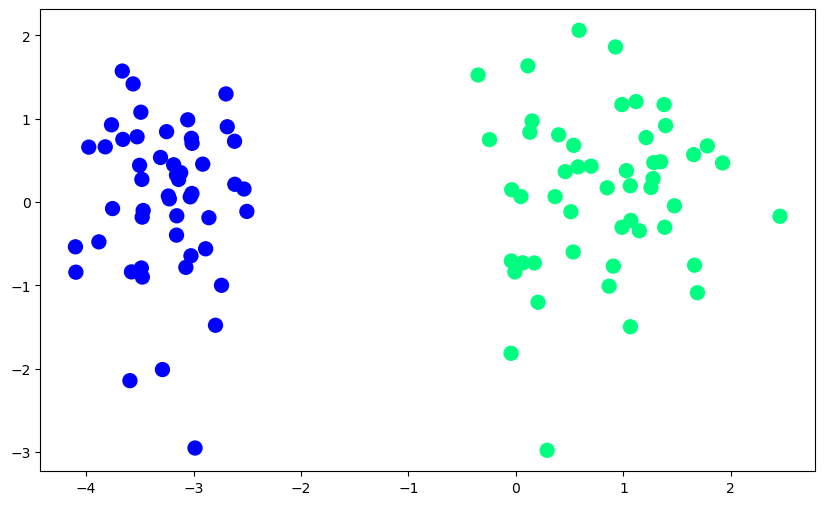

In [6]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [7]:
from sklearn.linear_model import LogisticRegression
lor = LogisticRegression(penalty =None,solver='sag')
lor.fit(X,y)

D:\shots\anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
D:\shots\anaconda\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",None
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass`

In [8]:
print(lor.coef_)
print(lor.intercept_)

[[4.92470449 0.23308658]]
[5.88506169]


In [9]:
m1 = - (lor.coef_[0][0]/lor.coef_[0][1])
b1 = - (lor.intercept_/lor.coef_[0][1])

In [10]:
x_input = np.linspace(-3,3,100)
y_input = m1*x_input + b1

In [11]:
def gd(X,y):
    X = np.insert(X,0,1,axis =1)
    weights =np.ones(X.shape[1])
    lr= 0.5
    for i in range(2500):
        y_hat = sigmoid(np.dot(X,weights))
        weights = weights+lr*(np.dot((y-y_hat),X)/X.shape[0])
    return weights[1:],weights[0]

In [12]:
def sigmoid(z):
    return 1/(1+ np.exp(-z))

In [13]:
coef_,intercept_ =gd(X,y)

In [14]:
m = - (coef_[0]/coef_[1])
b = - (intercept_/coef_[1])

In [15]:
x_input1 = np.linspace(-3,3,100)
y_input1 = m*x_input1 + b

(-3.0, 2.0)

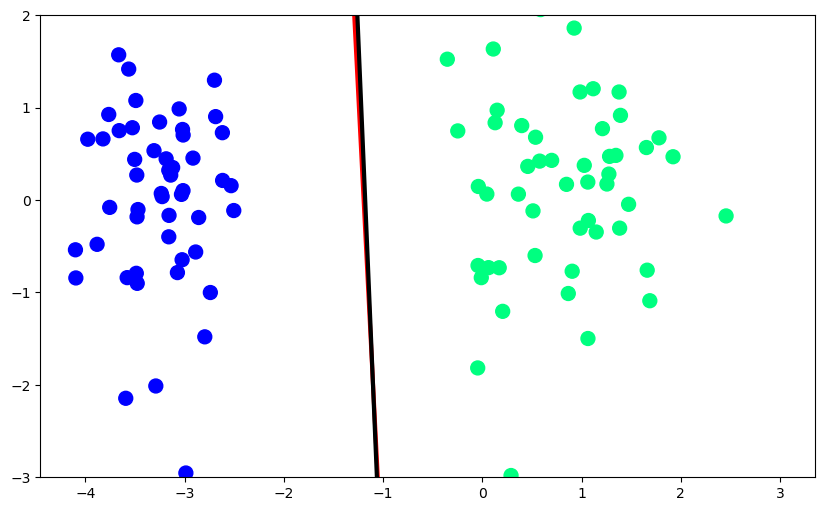

In [16]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.plot(x_input1,y_input1,color='black',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)



- see these  both are more neare than earlier
- 